# LAB 09 — Tokenizer & Label Alignment (BIO, subword, ignore index, Experiment 1)

Notebook này làm các phần *không cần huấn luyện*: BIO (mục 6–7), vấn đề subword & alignment (mục 8–11), shape (mục 15), phần core tokenization (mục 16) và **Experiment 1 – Tokenization Analysis** (mục 17). Mọi con số trong văn bản được sinh từ code ở cell trước nó (f-string), không gõ tay.

> Phần BIO/alignment/phân tích là suy luận của sinh viên; code do AI hỗ trợ — xem *AI-assisted* trong `README.md`.

In [1]:
import pandas as pd  # pandas truoc torch (Windows)
import numpy as np, json, random, re, collections, warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
import torch, transformers
from transformers import AutoTokenizer
import ner_core as nc

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 60)
tok = AutoTokenizer.from_pretrained(nc.MODEL_NAME)
data = nc.load_conll()
md = lambda s: display(Markdown(s))
md(f"Python/torch `{torch.__version__}`/transformers `{transformers.__version__}`; tokenizer `{nc.MODEL_NAME}` (WordPiece, cased, vocab {tok.vocab_size:,}, fast={tok.is_fast}). "
   f"CoNLL-2003: train {len(data['train']):,} / val {len(data['validation']):,} / test {len(data['test']):,} câu; nhãn `{nc.LABELS}`.")

Python/torch `2.12.0+cu126`/transformers `5.12.1`; tokenizer `bert-base-cased` (WordPiece, cased, vocab 28,996, fast=True). CoNLL-2003: train 14,041 / val 3,250 / test 3,453 câu; nhãn `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

## 1. Calculation Exercise 1 — BIO (mục 6)

`Elon Musk founded SpaceX in California.` với `Elon Musk → PER`, `SpaceX → ORG`, `California → LOC`.
Tự tạo token + nhãn BIO (viết tay ở cell dưới, rồi *kiểm tra* bằng `tags_to_entities` để chắc chuỗi nhãn đọc ngược ra đúng entity).

In [2]:
words = ["Elon", "Musk", "founded", "SpaceX", "in", "California", "."]
bio   = ["B-PER", "I-PER", "O", "B-ORG", "O", "B-LOC", "O"]                      # viết tay
assert nc.tags_to_entities(bio) == [("PER", 0, 2), ("ORG", 3, 4), ("LOC", 5, 6)]      # đọc ngược đúng 3 entity
display(pd.DataFrame({"token": words, "BIO label": bio}).T)
md(f"Số entity = {len(nc.tags_to_entities(bio))}; số token có nhãn `O` = {bio.count('O')}/{len(bio)}. "
   "`Elon Musk` là một entity 2 token nên có **một** `B-PER` (mở entity) và **một** `I-PER` (tiếp tục); `SpaceX`, `California` là entity 1 token nên chỉ có `B-`.")

,0,1,2,3,4,5,6
token,Elon,Musk,founded,SpaceX,in,California,.
BIO label,B-PER,I-PER,O,B-ORG,O,B-LOC,O


Số entity = 3; số token có nhãn `O` = 3/7. `Elon Musk` là một entity 2 token nên có **một** `B-PER` (mở entity) và **một** `I-PER` (tiếp tục); `SpaceX`, `California` là entity 1 token nên chỉ có `B-`.

## 2. Calculation Exercise 2 — Entity boundary (mục 7)

`University of California Berkeley` là một organization: `University→B-ORG, of→I-ORG, California→I-ORG, Berkeley→I-ORG`.
Nếu chỉ gán `ORG` cho mọi token (không có B/I), hai trường hợp *một entity dài* và *hai entity đứng sát nhau* không phân biệt được.

In [3]:
w = ["University", "of", "California", "Berkeley"]
one_entity   = ["B-ORG", "I-ORG", "I-ORG", "I-ORG"]
rows = []
# hai entity ORG đứng sát nhau (kiểu bảng kết quả bóng đá trong CoNLL): "Chelsea Arsenal"
w2 = ["Chelsea", "Arsenal"]
two_entities, one_long = ["B-ORG", "B-ORG"], ["B-ORG", "I-ORG"]
flat = ["ORG", "ORG"]       # nhãn phẳng, không có ranh giới
display(pd.DataFrame({
    "gán nhãn": ["University of California Berkeley: B-ORG I-ORG I-ORG I-ORG", "Chelsea Arsenal: B-ORG B-ORG", "Chelsea Arsenal: B-ORG I-ORG", "Chelsea Arsenal: ORG ORG (phẳng)"],
    "entity đọc ra": [str(nc.tags_to_entities(one_entity)), str(nc.tags_to_entities(two_entities)), str(nc.tags_to_entities(one_long)), "không xác định được: 1 hay 2 entity?"],
}))
md("**Vì sao không gán tất cả token là ORG?** NER không chỉ nhận ra *loại* mà còn phải nhận ra **ranh giới** (entity bắt đầu/kết thúc ở đâu). Với nhãn phẳng `ORG ORG ORG ORG` ta không phân biệt được "
   "`[University of California Berkeley]` (1 entity) với `[University of][California Berkeley]` (2 entity) hay hai tổ chức đứng liền nhau; hơn nữa đánh giá entity-level cần *span* chính xác. "
   "`B-` đánh dấu điểm bắt đầu nên hai entity liền kề cùng loại vẫn tách được; `I-` nói 'token này tiếp tục entity đang mở'.")

,gán nhãn,entity đọc ra
0,University of California Berkeley: B-ORG I-ORG I-ORG I-ORG,"[('ORG', 0, 4)]"
1,Chelsea Arsenal: B-ORG B-ORG,"[('ORG', 0, 1), ('ORG', 1, 2)]"
2,Chelsea Arsenal: B-ORG I-ORG,"[('ORG', 0, 2)]"
3,Chelsea Arsenal: ORG ORG (phẳng),không xác định được: 1 hay 2 entity?


**Vì sao không gán tất cả token là ORG?** NER không chỉ nhận ra *loại* mà còn phải nhận ra **ranh giới** (entity bắt đầu/kết thúc ở đâu). Với nhãn phẳng `ORG ORG ORG ORG` ta không phân biệt được `[University of California Berkeley]` (1 entity) với `[University of][California Berkeley]` (2 entity) hay hai tổ chức đứng liền nhau; hơn nữa đánh giá entity-level cần *span* chính xác. `B-` đánh dấu điểm bắt đầu nên hai entity liền kề cùng loại vẫn tách được; `I-` nói 'token này tiếp tục entity đang mở'.

## 3. Subword tokenization & label alignment problem (mục 8–9)

In [4]:
examples = ["playing", "Washington", "Schwarzenegger", "Obama", "Paris", "COVID-19", "U.S.", "Lumpur", "Dzhokhar", "unbelievably", "-DOCSTART-", "1996-08-22"]
rows = [{"word": e, "pieces": tok.tokenize(e), "#pieces": len(tok.tokenize(e))} for e in examples]
display(pd.DataFrame(rows))

,word,pieces,#pieces
0,playing,[playing],1
1,Washington,[Washington],1
2,Schwarzenegger,"[Sc, ##hwa, ##rz, ##ene, ##gger]",5
3,Obama,[Obama],1
4,Paris,[Paris],1
5,COVID-19,"[CO, ##VI, ##D, -, 19]",5
6,U.S.,"[U, ., S, .]",4
7,Lumpur,[Lumpur],1
8,Dzhokhar,"[D, ##z, ##ho, ##khar]",4
9,unbelievably,"[un, ##bel, ##ie, ##va, ##bly]",5


Dataset NER gán nhãn theo **word**, còn Transformer chạy trên **token ID** của subword ⇒ chuỗi token dài hơn chuỗi nhãn và `##ing` không có nhãn gốc.
Cell dưới lấy một câu thật của test set có entity bị tách và in `tokens / word_ids / nhãn` theo từng strategy.

In [5]:
test = data["test"]
def n_split_entity_words(rec):
    enc = tok(rec["tokens"], is_split_into_words=True)
    wids = enc.word_ids()
    cnt = collections.Counter(w for w in wids if w is not None)
    return sum(1 for i, t in enumerate(rec["tags"]) if t != "O" and cnt[i] > 1)
cand = [r for r in test if 6 <= len(r["tokens"]) <= 14 and n_split_entity_words(r) >= 1]
rec = cand[0]
enc = tok(rec["tokens"], is_split_into_words=True, truncation=True, padding=False)
wids = enc.word_ids()
A = nc.align_labels(wids, rec["tags"], "A"); B = nc.align_labels(wids, rec["tags"], "B")
name = lambda x: "IGNORE(-100)" if x == -100 else nc.LABELS[x]
df = pd.DataFrame({"token": tok.convert_ids_to_tokens(enc["input_ids"]), "input_id": enc["input_ids"], "attention_mask": enc["attention_mask"],
                   "word_id": wids, "word": [rec["tokens"][w] if w is not None else "—" for w in wids],
                   "word label": [rec["tags"][w] if w is not None else "—" for w in wids],
                   "Strategy A": [name(x) for x in A], "Strategy B": [name(x) for x in B]})
md(f"Câu test id `{rec['id']}`: `{' '.join(rec['tokens'])}` — {len(rec['tokens'])} word → {len(wids)} token (gồm `[CLS]`, `[SEP]`).")
display(df)

Câu test id `0`: `SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .` — 12 word → 33 token (gồm `[CLS]`, `[SEP]`).

,token,input_id,attention_mask,word_id,word,word label,Strategy A,Strategy B
0,[CLS],101,1,NaN,—,—,IGNORE(-100),IGNORE(-100)
1,S,156,1,0.0,SOCCER,O,O,O
2,##OC,9244,1,0.0,SOCCER,O,IGNORE(-100),O
3,##CE,10954,1,0.0,SOCCER,O,IGNORE(-100),O
4,##R,2069,1,0.0,SOCCER,O,IGNORE(-100),O
5,-,118,1,1.0,-,O,O,O
6,J,147,1,2.0,JAPAN,B-LOC,B-LOC,B-LOC
7,##AP,12240,1,2.0,JAPAN,B-LOC,IGNORE(-100),I-LOC
8,##AN,14962,1,2.0,JAPAN,B-LOC,IGNORE(-100),I-LOC
9,GE,25075,1,3.0,GET,O,O,O


### Chiến lược alignment được chọn: **Strategy A — nhãn cho subword đầu, còn lại `IGNORE` (−100)**

- **Vì sao**: (1) mỗi *word* có đúng một dự đoán ⇒ đánh giá và decode về word-level đơn giản, chuỗi nhãn của một câu không bị lẫn `I-X` do tokenizer tự sinh; (2) không "bịa" nhãn cho `##ing` — nhãn gốc là nhãn của *word*; (3) tương thích với cách model được pretrain/fine-tune phổ biến (BERT NER gốc cũng dùng subword đầu).
- **Áp dụng nhất quán**: cùng một hàm `align_labels(word_ids, labels, "A")` cho train/val/test; khi suy luận cũng lấy dự đoán tại **subword đầu** của mỗi word (`first_subword_positions`); metric tính ở mức word, giống gold CoNLL.
- **Đánh đổi**: các subword sau không được học trực tiếp; mất một phần tín hiệu huấn luyện (đo ở dưới). **Strategy B** (lan truyền `I-X`) được huấn luyện thêm 1 run để phân tích ảnh hưởng (`ner_finetuning.ipynb`).

### Ignore index (mục 11)

$L = -\frac{1}{|\{i: y_i \neq IGNORE\}|}\sum_{i: y_i \neq IGNORE} \log P(y_i \mid x)$ — `ignore_index=-100` của `CrossEntropyLoss`.

In [6]:
# Tính tay loss với/không có IGNORE và so với nc.token_loss; rồi chứng minh token IGNORE vẫn "tồn tại" trong attention.
torch.manual_seed(0)
Z = torch.randn(1, len(wids), 9)                                  # logits giả [B=1,T,C=9]
lab = torch.tensor([A])
m = lab != -100
lp = torch.log_softmax(Z, -1)
manual = -(lp[m].gather(1, lab[m].unsqueeze(1))).mean()
assert torch.allclose(manual, nc.token_loss(Z, lab), atol=1e-6)
md(f"Có {int(m.sum())} token tính loss / {len(wids)} token (bỏ {int((~m).sum())}: `[CLS]`, `[SEP]` và subword không đầu). Loss tay = {float(manual):.4f} = `token_loss` = {float(nc.token_loss(Z, lab)):.4f}.")

# IGNORE chỉ nghĩa là "nhãn không dùng trong loss", chứ token vẫn đi qua encoder và ảnh hưởng đến token khác:
model = nc.TokenClassifier().eval()
ids = torch.tensor([enc["input_ids"]]); mask = torch.ones_like(ids)
with torch.no_grad():
    h_full = model.hidden_states(ids, mask)[0]
    mask2 = mask.clone(); ign = [i for i, x in enumerate(A) if x == -100 and wids[i] is not None]
    mask2[0, ign] = 0                                               # che các subword bị IGNORE (không cho ai attend tới)
    h_cut = model.hidden_states(ids, mask2)[0]
first = [i for i, x in enumerate(A) if x != -100]
shift = (h_full[first] - h_cut[first]).norm(dim=-1)
md(f"Che các subword bị IGNORE khỏi attention làm biểu diễn của {len(first)} token có nhãn đổi trung bình {float(shift.mean()):.3f} (L2; max {float(shift.max()):.3f}) ⇒ "
   "token IGNORE **không bị bỏ đi** — nó vẫn góp ngữ cảnh cho token khác; chỉ là *nhãn* của nó không tạo gradient trực tiếp.")

Có 12 token tính loss / 33 token (bỏ 21: `[CLS]`, `[SEP]` và subword không đầu). Loss tay = 2.5163 = `token_loss` = 2.5163.

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 6712.03it/s]


[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Che các subword bị IGNORE khỏi attention làm biểu diễn của 12 token có nhãn đổi trung bình 10.598 (L2; max 12.222) ⇒ token IGNORE **không bị bỏ đi** — nó vẫn góp ngữ cảnh cho token khác; chỉ là *nhãn* của nó không tạo gradient trực tiếp.

## 4. Calculation Exercise 3 — Shape (mục 15)

$B=8,\; T=128,\; d=768,\; C=9$ ⇒ hidden $H: B\times T\times d$, logits $Z=HW+b: B\times T\times C$ với $W\in\mathbb{R}^{d\times C}$, labels $Y: B\times T$.
Kiểm chứng bằng model thật (`bert-base-cased`, $d$ lấy từ config):

In [7]:
B, T, C = 8, 128, 9
model = nc.TokenClassifier().eval()
d = model.encoder.config.hidden_size
ids = torch.randint(1000, 5000, (B, T)); mask = torch.ones(B, T, dtype=torch.long); Y = torch.randint(0, C, (B, T))
with torch.no_grad():
    H = model.hidden_states(ids, mask); Zt = model(ids, mask)
head_params = sum(p.numel() for p in model.classifier.parameters())
tot, trn = nc.count_parameters(model)
display(pd.DataFrame({"tensor": ["hidden states H", "logits Z", "labels Y", "weight W", "bias b"],
                      "shape": [tuple(H.shape), tuple(Zt.shape), tuple(Y.shape), tuple(model.classifier.weight.T.shape), tuple(model.classifier.bias.shape)],
                      "công thức": ["B×T×d", "B×T×C", "B×T", "d×C", "C"]}))
assert tuple(H.shape) == (8, 128, 768) and tuple(Zt.shape) == (8, 128, 9)
md(f"Head có {head_params:,} tham số = {d}×{C} + {C}; encoder {tot - head_params:,}; tổng {tot:,} (đều trainable khi fine-tune toàn bộ). "
   f"Số vector logits cho một batch = B·T = {B*T:,} (mỗi token một vector ∈ ℝ^{C}), trong đó chỉ những vị trí có nhãn ≠ −100 góp vào loss. Với Strategy A, cross-entropy lấy trung bình trên các vị trí đó.")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 5119.57it/s]


[transformers] BertModel LOAD REPORT from: bert-base-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
bert.pooler.dense.bias                     | UNEXPECTED |  | 
bert.pooler.dense.weight                   | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,tensor,shape,công thức
0,hidden states H,"(8, 128, 768)",B×T×d
1,logits Z,"(8, 128, 9)",B×T×C
2,labels Y,"(8, 128)",B×T
3,weight W,"(768, 9)",d×C
4,bias b,"(9,)",C


Head có 6,921 tham số = 768×9 + 9; encoder 107,719,680; tổng 107,726,601 (đều trainable khi fine-tune toàn bộ). Số vector logits cho một batch = B·T = 1,024 (mỗi token một vector ∈ ℝ^9), trong đó chỉ những vị trí có nhãn ≠ −100 góp vào loss. Với Strategy A, cross-entropy lấy trung bình trên các vị trí đó.

## 5. Core: `tokenizer(words, is_split_into_words=True, ...)` (mục 16)

Cell dưới in đủ `tokens / input_ids / attention_mask / word_ids / labels` cho một batch 2 câu (có padding), đúng như đề yêu cầu; phần `logits / predictions` nằm ở `ner_finetuning.ipynb`.

In [8]:
batch_words = [["Barack", "Obama", "visited", "Paris", "."], ["Schwarzenegger", "supports", "Hawthorne", "FC"]]
enc2 = tok(batch_words, is_split_into_words=True, truncation=True, padding=True, return_tensors="pt")
for k in range(2):
    wk = enc2.word_ids(k)
    md(f"**Câu {k}** `{' '.join(batch_words[k])}`")
    display(pd.DataFrame({"token": tok.convert_ids_to_tokens(enc2["input_ids"][k]), "input_ids": enc2["input_ids"][k].tolist(),
                          "attention_mask": enc2["attention_mask"][k].tolist(), "word_ids": wk}).T)
md(f"`input_ids.shape = {tuple(enc2['input_ids'].shape)}`, `attention_mask.shape = {tuple(enc2['attention_mask'].shape)}`; token padding (`[PAD]`, `word_id=None`) có mask 0 và nhãn −100.")

**Câu 0** `Barack Obama visited Paris .`

,0,1,2,3,4,5,6,7,8,9
token,[CLS],Barack,Obama,visited,Paris,.,[SEP],[PAD],[PAD],[PAD]
input_ids,101,14319,7661,3891,2123,119,102,0,0,0
attention_mask,1,1,1,1,1,1,1,0,0,0
word_ids,NaN,0.0,1.0,2.0,3.0,4.0,NaN,NaN,NaN,NaN


**Câu 1** `Schwarzenegger supports Hawthorne FC`

,0,1,2,3,4,5,6,7,8,9
token,[CLS],Sc,##hwa,##rz,##ene,##gger,supports,Hawthorne,FC,[SEP]
input_ids,101,20452,24156,11819,7582,9146,6253,26220,3604,102
attention_mask,1,1,1,1,1,1,1,1,1,1
word_ids,NaN,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.0,NaN


`input_ids.shape = (2, 10)`, `attention_mask.shape = (2, 10)`; token padding (`[PAD]`, `word_id=None`) có mask 0 và nhãn −100.

## 6. Experiment 1 — Tokenization Analysis (mục 17)

Mẫu: **30 câu** của test set, chọn ngẫu nhiên có seed 42 — 15 câu ngắn (5–9 word) và 15 câu dài (≥ 25 word). Thống kê `# words`, `# tokens` (không tính `[CLS]/[SEP]`), `# subword splits` (số word bị tách thành ≥ 2 piece), và $R = \#\text{subword tokens}/\#\text{words}$ với #subword tokens = số token WordPiece của câu (không tính special). Sau đó mở rộng ra toàn bộ test set để so sánh entity / non-entity và loại từ.

In [9]:
def piece_counts(rec):
    enc = tok(rec["tokens"], is_split_into_words=True)
    c = collections.Counter(w for w in enc.word_ids() if w is not None)
    return [c[i] for i in range(len(rec["tokens"]))]                  # số piece của từng word

rng = random.Random(42)
short = [r for r in test if 5 <= len(r["tokens"]) <= 9]; long_ = [r for r in test if len(r["tokens"]) >= 25]
sample = [("short", r) for r in rng.sample(short, 15)] + [("long", r) for r in rng.sample(long_, 15)]
rows = []
for kind, r in sample:
    pc = piece_counts(r)
    rows.append({"id": r["id"], "group": kind, "# words": len(pc), "# tokens": sum(pc), "# subword splits": sum(p > 1 for p in pc),
                 "R": sum(pc) / len(pc), "# entity words": sum(t != "O" for t in r["tags"]), "text": " ".join(r["tokens"])[:70]})
sdf = pd.DataFrame(rows)
display(sdf.round(3))
g = sdf.groupby("group")[["# words", "# tokens", "# subword splits"]].sum()
g["R"] = g["# tokens"] / g["# words"]; g["splits per 10 words"] = 10 * g["# subword splits"] / g["# words"]
display(g.loc[["short", "long"]].round(3))
md(f"Trên 30 câu mẫu: R chung = {sdf['# tokens'].sum() / sdf['# words'].sum():.3f}; câu ngắn R = {g.loc['short','R']:.3f}, câu dài R = {g.loc['long','R']:.3f}.")

,id,group,# words,# tokens,# subword splits,R,# entity words,text
0,525,short,6,11,3,1.833,1,DETROIT 5 8 0 263 289
1,116,short,8,12,3,1.500,5,B. Young c Moin Khan b Waqar 5
2,1824,short,6,6,0,1.000,0,Week to Date - None .
3,1615,short,9,11,2,1.222,2,Est daily livestock slaughter under Fed inspection - USDA
4,1293,short,7,9,1,1.286,1,Polish ex-communist president to visit Pope .
5,628,short,7,7,0,1.000,2,"70 , Phil Gray 89 ) ."
6,502,short,6,13,2,2.167,1,JACKSONVILLE 6 7 0 263 288
7,3200,short,9,29,6,3.222,1,SOCCER - ISRAELI FIRST DIVISION RESULTS / STANDINGS .
8,450,short,5,11,2,2.200,1,CLEVELAND 11 5 .688 5
9,3352,short,7,12,1,1.714,1,VANCOUVER 14 11 1 84 83 29


,# words,# tokens,# subword splits,R,splits per 10 words
group,,,,,
short,105,196,37,1.867,3.524
long,487,581,59,1.193,1.211


Trên 30 câu mẫu: R chung = 1.312; câu ngắn R = 1.867, câu dài R = 1.193.

In [10]:
# Toàn bộ test set: entity vs non-entity, theo loại entity, theo loại từ, theo tần suất trong train.
train_freq = collections.Counter(w for r in data["train"] for w in r["tokens"])
recs = []
for r in test:
    pc = piece_counts(r)
    for i, (w, t) in enumerate(zip(r["tokens"], r["tags"])):
        recs.append({"word": w, "tag": t, "etype": t[2:] if t != "O" else "O", "pieces": pc[i], "in_train": train_freq[w] > 0, "train_freq": train_freq[w]})
W = pd.DataFrame(recs)
W["entity"] = np.where(W.etype == "O", "non-entity", "entity")
def category(w):
    if re.fullmatch(r"[^\w\s]+", w): return "punctuation"
    if any(ch.isdigit() for ch in w): return "contains digit"
    if "-" in w: return "hyphenated"
    if w.isupper() and len(w) > 1: return "ALL CAPS"
    if w[0].isupper(): return "Capitalized"
    return "lowercase"
W["category"] = W.word.map(category)
W["split"] = W.pieces > 1
def summarize(by):
    t = W.groupby(by).agg(words=("word", "size"), tokens=("pieces", "sum"), split_words=("split", "sum"))
    t["R = tokens/words"] = t.tokens / t.words; t["% words split"] = 100 * t.split_words / t.words
    return t.round(3)
md("**Entity vs non-entity** (toàn bộ test set)"); display(summarize("entity"))
md("**Theo loại entity**"); display(summarize("etype").loc[["PER", "ORG", "LOC", "MISC", "O"]])
md("**Theo loại từ** (quy tắc đơn giản theo ký tự)"); display(summarize("category").sort_values("R = tokens/words", ascending=False))
W["train_bucket"] = pd.cut(W.train_freq, [-1, 0, 4, 49, 10**9], labels=["unseen (0)", "rare (1-4)", "mid (5-49)", "frequent (>=50)"])
md("**Theo tần suất của word trong train**"); display(summarize("train_bucket"))
cnt = W[W.split].groupby("word").agg(n=("word", "size"), pieces=("pieces", "first")).sort_values("n", ascending=False).head(15)
cnt["tokens"] = [tok.tokenize(w) for w in cnt.index]
md("**15 word bị tách thường gặp nhất trong test**"); display(cnt)

**Entity vs non-entity** (toàn bộ test set)

,words,tokens,split_words,R = tokens/words,% words split
entity,,,,,
entity,8112,15536,3673,1.915,45.279
non-entity,38323,47925,4614,1.251,12.040


**Theo loại entity**

,words,tokens,split_words,R = tokens/words,% words split
etype,,,,,
PER,2773,5699,1660,2.055,59.863
ORG,2496,4833,1127,1.936,45.152
LOC,1925,3416,600,1.775,31.169
MISC,918,1588,286,1.730,31.155
O,38323,47925,4614,1.251,12.040


**Theo loại từ** (quy tắc đơn giản theo ký tự)

,words,tokens,split_words,R = tokens/words,% words split
category,,,,,
hyphenated,362,1441,362,3.981,100.000
ALL CAPS,1923,6283,1666,3.267,86.635
contains digit,5883,10701,1995,1.819,33.911
Capitalized,8891,13619,2824,1.532,31.762
lowercase,23506,25465,1370,1.083,5.828
punctuation,5870,5952,70,1.014,1.193


**Theo tần suất của word trong train**

,words,tokens,split_words,R = tokens/words,% words split
train_bucket,,,,,
unseen (0),5656,15475,4447,2.736,78.624
rare (1-4),4533,7511,1574,1.657,34.723
mid (5-49),10480,13207,1344,1.260,12.824
frequent (>=50),25766,27268,922,1.058,3.578


**15 word bị tách thường gặp nhất trong test**

,n,pieces,tokens
word,,,
's,330,2,"[', s]"
1996-12-06,165,5,"[1996, -, 12, -, 06]"
--,58,2,"[-, -]"
U.S.,51,4,"[U, ., S, .]"
1996-12-07,51,5,"[1996, -, 12, -, 07]"
SOCCER,42,4,"[S, ##OC, ##CE, ##R]"
NEW,37,2,"[NE, ##W]"
DIVISION,35,5,"[D, ##I, ##VI, ##SI, ##ON]"
LONDON,31,4,"[L, ##ON, ##D, ##ON]"


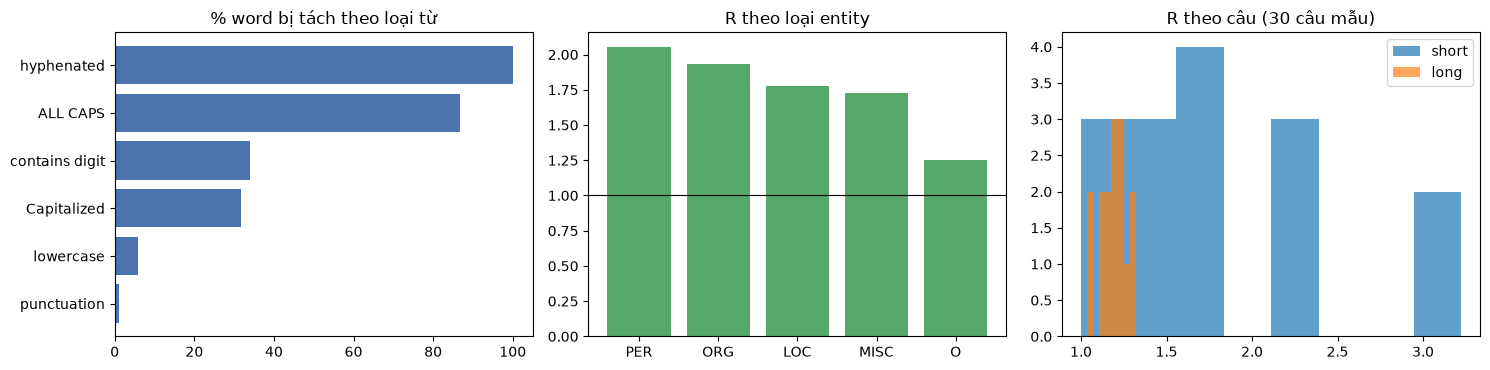

- Toàn test: R = 1.367; 17.85% word bị tách. **Entity** R = 1.915 (45.3% bị tách) so với **non-entity** R = 1.251 (12.0%).
- Word *unseen* trong train: R = 2.736 (78.6% bị tách); word thường gặp (≥ 50 lần): R = 1.058 (3.6%).
- Số word bị tách thành ≥ 2 piece: 8,287/46,435; trong đó là entity: 3,673/8,112 word entity (45.3%).

In [11]:
# Hình: % word bị tách theo loại từ và theo entity type
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
c = summarize("category").sort_values("% words split"); ax[0].barh(c.index, c["% words split"], color="#4C72B0"); ax[0].set_title("% word bị tách theo loại từ")
e = summarize("etype").loc[["PER", "ORG", "LOC", "MISC", "O"]]; ax[1].bar(e.index, e["R = tokens/words"], color="#55A868"); ax[1].axhline(1, color="k", lw=.8); ax[1].set_title("R theo loại entity")
ax[2].hist(sdf[sdf.group == "short"].R, bins=8, alpha=.7, label="short"); ax[2].hist(sdf[sdf.group == "long"].R, bins=8, alpha=.7, label="long"); ax[2].legend(); ax[2].set_title("R theo câu (30 câu mẫu)")
plt.tight_layout(); plt.savefig("tokenization_analysis.png", dpi=130); plt.show()

ent = summarize("entity"); tr = summarize("train_bucket")
md(f"- Toàn test: R = {W.pieces.sum() / len(W):.3f}; {100 * W.split.mean():.2f}% word bị tách. **Entity** R = {ent.loc['entity','R = tokens/words']:.3f} ({ent.loc['entity','% words split']:.1f}% bị tách) so với **non-entity** R = {ent.loc['non-entity','R = tokens/words']:.3f} ({ent.loc['non-entity','% words split']:.1f}%).\n"
   f"- Word *unseen* trong train: R = {tr.loc['unseen (0)','R = tokens/words']:.3f} ({tr.loc['unseen (0)','% words split']:.1f}% bị tách); word thường gặp (≥ 50 lần): R = {tr.loc['frequent (>=50)','R = tokens/words']:.3f} ({tr.loc['frequent (>=50)','% words split']:.1f}%).\n"
   f"- Số word bị tách thành ≥ 2 piece: {int(W.split.sum()):,}/{len(W):,}; trong đó là entity: {int((W.split & (W.entity=='entity')).sum()):,}/{int((W.entity=='entity').sum()):,} word entity ({100*(W.split & (W.entity=='entity')).sum()/(W.entity=='entity').sum():.1f}%).")

In [12]:
# Tác động của Strategy A lên nhãn (toàn bộ train): bao nhiêu subword bị IGNORE, bao nhiêu nhãn entity nằm ở subword đầu
tr_ds = nc.NERDataset(data["train"], tok, "A", 256); tr_dsB = nc.NERDataset(data["train"], tok, "B", 256)
labA = np.concatenate([np.array(it["labels"]) for it in tr_ds.items]); labB = np.concatenate([np.array(it["labels"]) for it in tr_dsB.items])
n_special = 2 * len(tr_ds); n_tok = sum(len(it["input_ids"]) for it in tr_ds.items); n_words = sum(len(r["tokens"]) for r in data["train"])
ignored_sub = int((labA == -100).sum()) - n_special
md(f"Train: {n_words:,} word → {n_tok:,} token (gồm {n_special:,} special) ⇒ R = {(n_tok - n_special) / n_words:.3f}.\n\n"
   f"- **Strategy A**: {int((labA != -100).sum()):,} token có nhãn (= số word), {ignored_sub:,} subword không đầu bị IGNORE ({100 * ignored_sub / (n_tok - n_special):.1f}% non-special token), {n_special:,} special token bị IGNORE.\n"
   f"- **Strategy B**: {int((labB != -100).sum()):,} token có nhãn; thêm {int((labB != -100).sum() - (labA != -100).sum()):,} nhãn do tokenizer tự sinh cho subword không đầu "
   f"({int(sum(1 for x in labB if x in (nc.LABEL2ID['I-PER'], nc.LABEL2ID['I-ORG'], nc.LABEL2ID['I-LOC'], nc.LABEL2ID['I-MISC'])) - sum(1 for x in labA if x in (nc.LABEL2ID['I-PER'], nc.LABEL2ID['I-ORG'], nc.LABEL2ID['I-LOC'], nc.LABEL2ID['I-MISC']))):,} trong đó là `I-X`).\n"
   f"- Không có word nào bị mất hết piece; truncation `max_len=256`: train/val/test bị cắt lần lượt {tr_ds.n_truncated_sentences}/{nc.NERDataset(data['validation'], tok, 'A', 256).n_truncated_sentences}/{nc.NERDataset(data['test'], tok, 'A', 256).n_truncated_sentences} câu "
   f"(câu dài nhất {max(len(it['input_ids']) for it in tr_ds.items)} token ≤ 256).")

Train: 203,621 word → 300,677 token (gồm 28,082 special) ⇒ R = 1.339.

- **Strategy A**: 203,621 token có nhãn (= số word), 68,974 subword không đầu bị IGNORE (25.3% non-special token), 28,082 special token bị IGNORE.
- **Strategy B**: 272,595 token có nhãn; thêm 68,974 nhãn do tokenizer tự sinh cho subword không đầu (30,987 trong đó là `I-X`).
- Không có word nào bị mất hết piece; truncation `max_len=256`: train/val/test bị cắt lần lượt 0/0/0 câu (câu dài nhất 173 token ≤ 256).

### Kết luận Experiment 1 (trả lời *Những loại từ nào thường bị chia thành nhiều subword?*)

In [13]:
cat = summarize("category"); et = summarize("etype"); tb = summarize("train_bucket")
top = cat.sort_values("% words split", ascending=False)
NL = chr(10)
parts = [
    "**Loại từ bị tách nhiều nhất** (toàn test): " + "; ".join(f"{k} {v['% words split']:.1f}% (R={v['R = tokens/words']:.2f})" for k, v in top.head(4).iterrows())
    + ". Ít bị tách nhất: " + "; ".join(f"{k} {v['% words split']:.1f}%" for k, v in top.tail(2).iterrows()) + ".",
    f"- **Tần suất**: word chưa từng thấy ở train bị tách {tb.loc['unseen (0)','% words split']:.1f}% so với {tb.loc['frequent (>=50)','% words split']:.1f}% ở word thường gặp (>= 50 lần) — vocab WordPiece ({tok.vocab_size:,} mục) chứa nguyên các từ phổ biến, từ hiếm bị vỡ thành mảnh.",
    f"- **Entity vs non-entity**: entity bị tách {ent.loc['entity','% words split']:.1f}% (R={ent.loc['entity','R = tokens/words']:.2f}) so với {ent.loc['non-entity','% words split']:.1f}% (R={ent.loc['non-entity','R = tokens/words']:.2f}); PER cao nhất (R={et.loc['PER','R = tokens/words']:.2f}) vì tên người ngoại quốc ít gặp, LOC/MISC thấp hơn ({et.loc['LOC','R = tokens/words']:.2f}/{et.loc['MISC','R = tokens/words']:.2f}) vì nhiều địa danh phổ biến nằm sẵn trong vocab (`Paris`, `Japan`).",
    f"- **Câu ngắn vs dài**: R câu ngắn = {g.loc['short','R']:.2f} > câu dài = {g.loc['long','R']:.2f}. Không phải vì câu ngắn 'khó tokenize' hơn mà vì thành phần: câu ngắn của CoNLL phần lớn là tiêu đề IN HOA (`SOCCER - JAPAN GET LUCKY WIN`), dòng kết quả/tỉ số và ngày tháng (`DETROIT 5 8 0 263 289`) — toàn ALL CAPS, số, gạch nối — còn câu dài là văn xuôi chữ thường. Nên R phụ thuộc *loại từ* hơn là độ dài câu.",
    "Hệ quả: Strategy A bỏ nhãn của các subword không đầu, đúng ở những entity khó nhất (tên riêng hiếm); alignment không phải chi tiết kỹ thuật vụn vặt.",
]
md((NL + NL).join(parts))

**Loại từ bị tách nhiều nhất** (toàn test): hyphenated 100.0% (R=3.98); ALL CAPS 86.6% (R=3.27); contains digit 33.9% (R=1.82); Capitalized 31.8% (R=1.53). Ít bị tách nhất: lowercase 5.8%; punctuation 1.2%.

- **Tần suất**: word chưa từng thấy ở train bị tách 78.6% so với 3.6% ở word thường gặp (>= 50 lần) — vocab WordPiece (28,996 mục) chứa nguyên các từ phổ biến, từ hiếm bị vỡ thành mảnh.

- **Entity vs non-entity**: entity bị tách 45.3% (R=1.92) so với 12.0% (R=1.25); PER cao nhất (R=2.06) vì tên người ngoại quốc ít gặp, LOC/MISC thấp hơn (1.77/1.73) vì nhiều địa danh phổ biến nằm sẵn trong vocab (`Paris`, `Japan`).

- **Câu ngắn vs dài**: R câu ngắn = 1.87 > câu dài = 1.19. Không phải vì câu ngắn 'khó tokenize' hơn mà vì thành phần: câu ngắn của CoNLL phần lớn là tiêu đề IN HOA (`SOCCER - JAPAN GET LUCKY WIN`), dòng kết quả/tỉ số và ngày tháng (`DETROIT 5 8 0 263 289`) — toàn ALL CAPS, số, gạch nối — còn câu dài là văn xuôi chữ thường. Nên R phụ thuộc *loại từ* hơn là độ dài câu.

Hệ quả: Strategy A bỏ nhãn của các subword không đầu, đúng ở những entity khó nhất (tên riêng hiếm); alignment không phải chi tiết kỹ thuật vụn vặt.